#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [1]:
%pip install -q pystac-client rasterio pillow matplotlib numpy

In [2]:
# had to reorder the imports, sorry...
import json
from pathlib import Path

import numpy as np
import rasterio
import matplotlib.pyplot as plt

from PIL import Image
from pystac_client import Client
from rasterio.windows import Window
from rasterio.warp import transform
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

In [3]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

Mark how we have used the command $matrix$ to generate a matrix from the image!

> First of all it changes the type of data (obviously!)

In [4]:
# extra checks if path exists
print("drive: ", [i for i in Path("/content/drive").absolute().iterdir()])
print("MyDrive: ", [i for i in Path("/content/drive/MyDrive").absolute().iterdir() if i.suffix.lower() == ".jpg"])

drive:  [PosixPath('/content/drive/.shortcut-targets-by-id'), PosixPath('/content/drive/MyDrive'), PosixPath('/content/drive/Othercomputers'), PosixPath('/content/drive/.Trash-0'), PosixPath('/content/drive/.Encrypted')]
MyDrive:  [PosixPath('/content/drive/MyDrive/Skrzypczyk Szymon 8+T.JPG'), PosixPath('/content/drive/MyDrive/IMG_4294.jpg'), PosixPath('/content/drive/MyDrive/tlo_online.jpg'), PosixPath('/content/drive/MyDrive/att.M9m-USC6psCL51Wd7BkpkzQz7YTGjR7QYD1p3ttznfw.jpg'), PosixPath('/content/drive/MyDrive/5b99ffe7-1665-4dfb-a1aa-ef6dbfbcc8dc.JPG')]


In [5]:
img = Image.open("/content/drive/My Drive/5b99ffe7-1665-4dfb-a1aa-ef6dbfbcc8dc.JPG")
imggray = img.convert('L')

original type: <class 'numpy.ndarray'>
matrix type: <class 'numpy.matrix'>


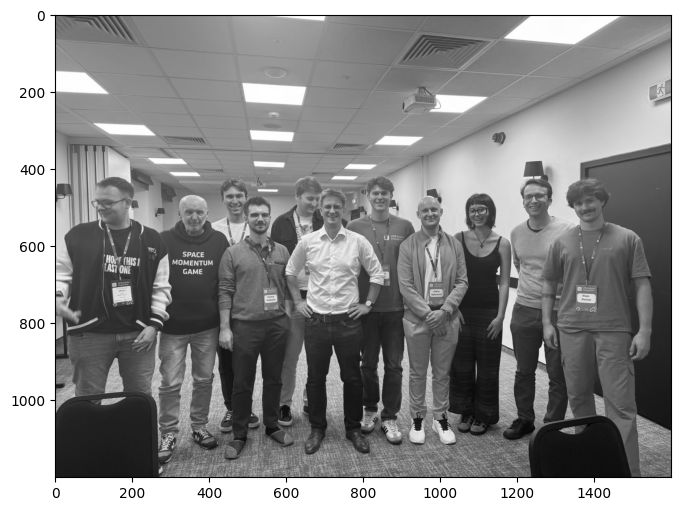

In [6]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
print(f"original type: {type(imgmat)}")
imgmat = np.matrix(imgmat)
print(f"matrix type: {type(imgmat)}")
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

PFR school of pioneers :)

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

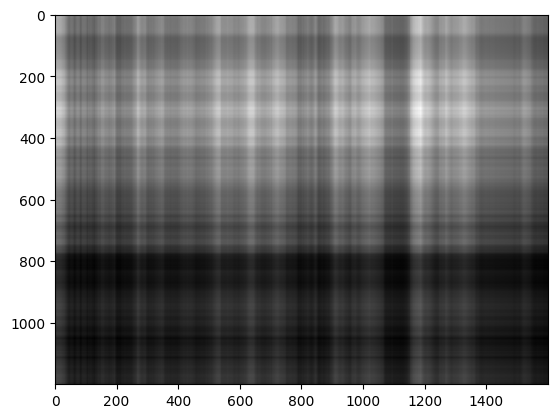

In [7]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

What do you observe?

> the plot of sigma falls rapidly and eventually approaches zero for higher indices, it means that the first values are the most meaningful, my hypothesis being their removal will completely kill the quality of reconstructed image

How many vecotrs can we use to get a decent reconstruction of the image?

> I believe that based on my testing over 50 is a good number for quite an acceptable quality, over 100 is near perfect


What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

> the quality of the image will completely deteriorate, as the two most meaningful vectors will be gone and they contain most information about the image


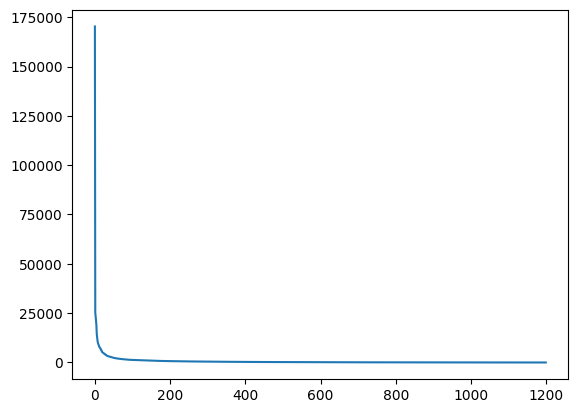

In [8]:
U.shape
sigma.shape
plt.plot(sigma)

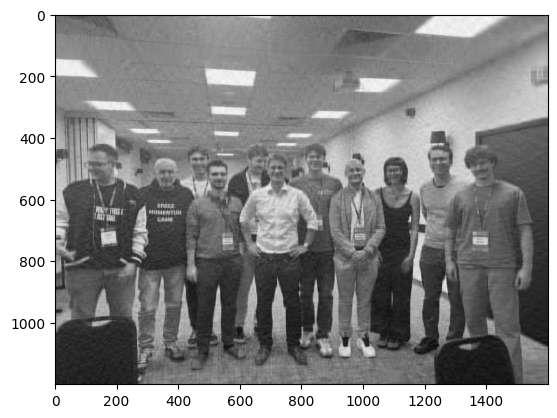

In [9]:
i = 70
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

It's quite visible that there is a quality loss endured by the reconstructed image in comparison to the original one (I'm still able to detect faces though!). The lower `i` is the worse the final quality is (while not changing the `j`), while increasing `j` param while not changing the `i` param renders the image completely unreadable, example for `i=70, j=50`:

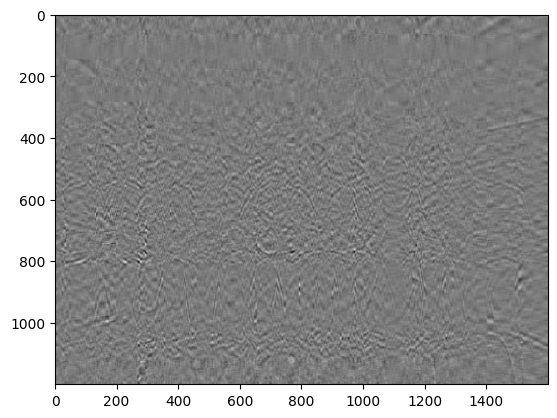

It's worth noting that the params are basically coordinates inside the matrix, singular values control the quality of reconstructed image.

Also increasing the `i` parameter increases the quality of the image (quite instinctively too)

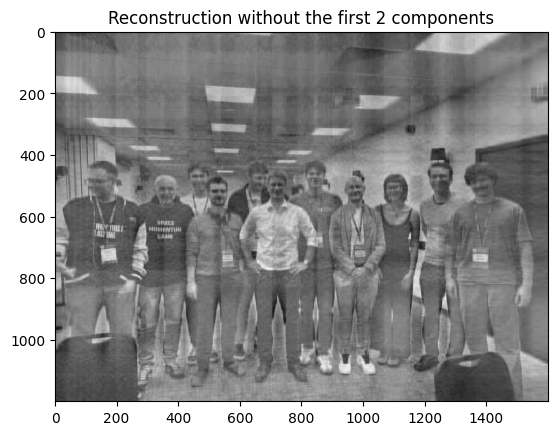

In [10]:
# Test for my hypothesis, surely enough the quality is massively affected
i = 70
j = 2

reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray')
plt.title("Reconstruction without the first 2 components")
plt.show()

## Questions from UPEL for previous tasks

1. Run SVD on the images and note your observations. How many eigenvalues are good enough?

As previously I believe over 50 is enough for decent quality reconstrction, while about 100 eigenvalues is a near perfect reconstruction

2. In stead of using the largest $k$ Eigen values, if you use 10th, 11th,,,,k+10 engine values, would you get better images?

No, the first eigenvalues are the most meaningful and hold the most information, as such skipping the first 10 observations loses most of quality to be reconstructed - lowering the quality

3. will be a separate cell or a bunch of cells :)

#### Satellite images

I have selected 3 images for ubran, forest and sea conditions:

- Forest - Puszcza Niepołomicka

- Urban - Kraków

- Sea - Baltic Sea



## Show selected images

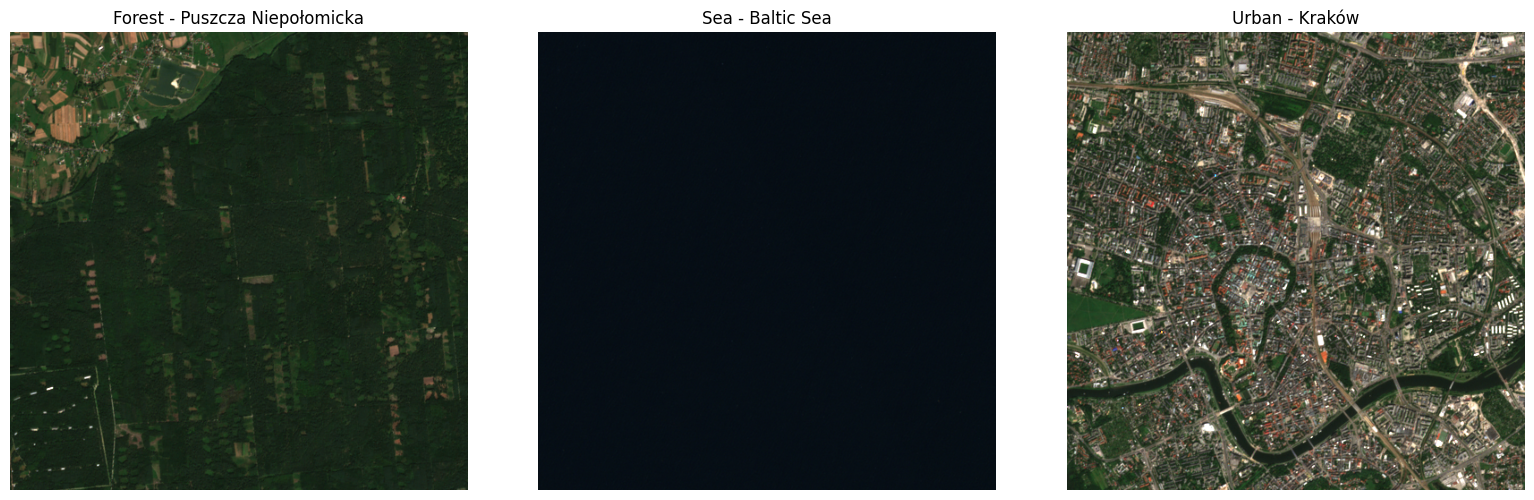

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

PATHS = {
    "Forest": "/content/drive/MyDrive/AI_LABS/lab1/forest_puszcza_niepolomicka.png",
    "Sea": "/content/drive/MyDrive/AI_LABS/lab1/sea_baltic.png",
    "Urban": "/content/drive/MyDrive/AI_LABS/lab1/urban_krakow.png"
}

titles = [
    "Forest - Puszcza Niepołomicka",
    "Sea - Baltic Sea",
    "Urban - Kraków"
]

for ax, img_path, title in zip(axes, PATHS.values(), titles):

    img = Image.open(img_path)

    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

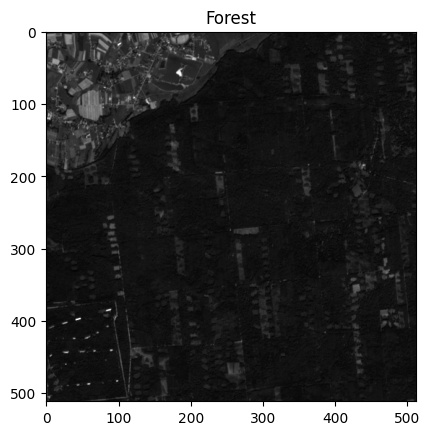

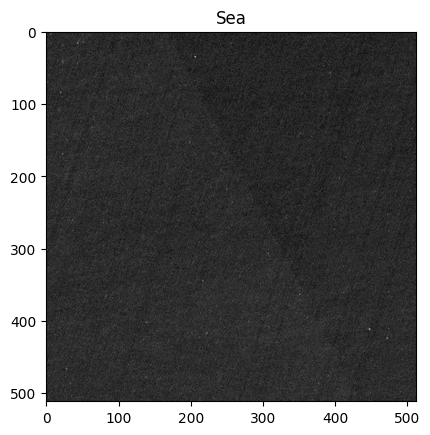

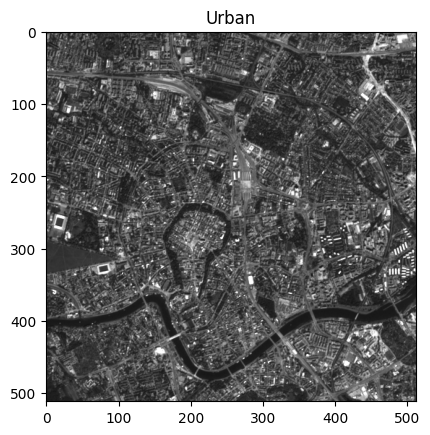

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import structural_similarity as ssim

images = {}

for name, path in PATHS.items():
    img = Image.open(path)
    imggray = img.convert('L')
    imgmat = np.matrix(np.array(imggray, dtype=float))

    images[name] = imgmat

    plt.imshow(imgmat, cmap='gray')
    plt.title(name)
    plt.show()

## Comparison of different eigenvalues influence on the reconstruction of the images

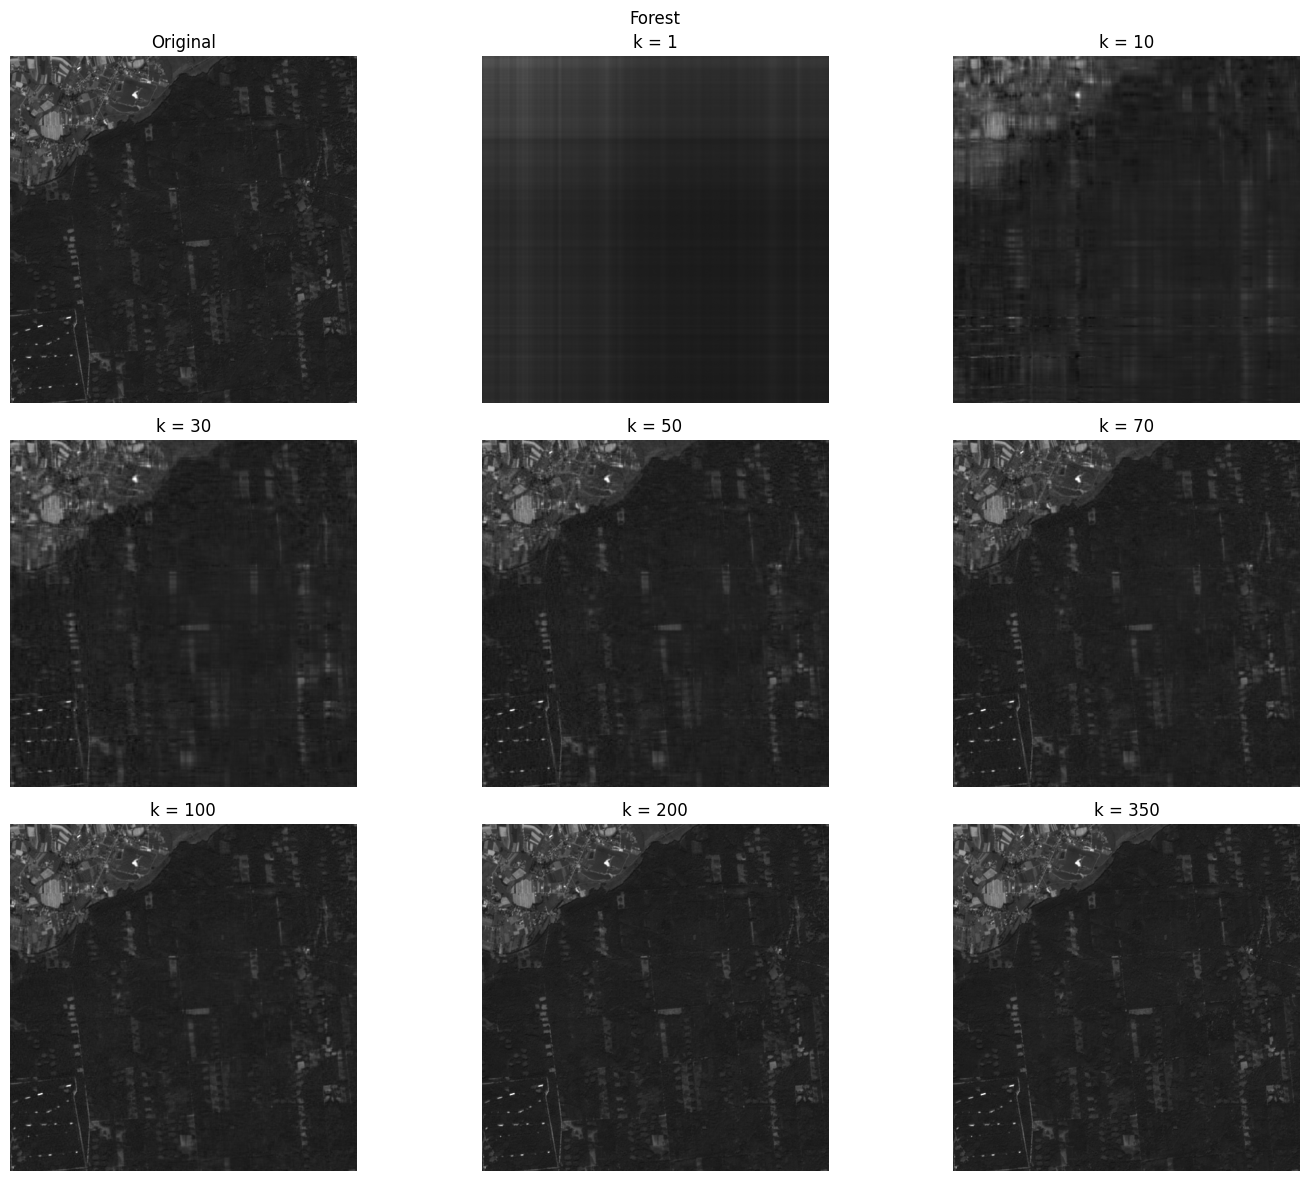

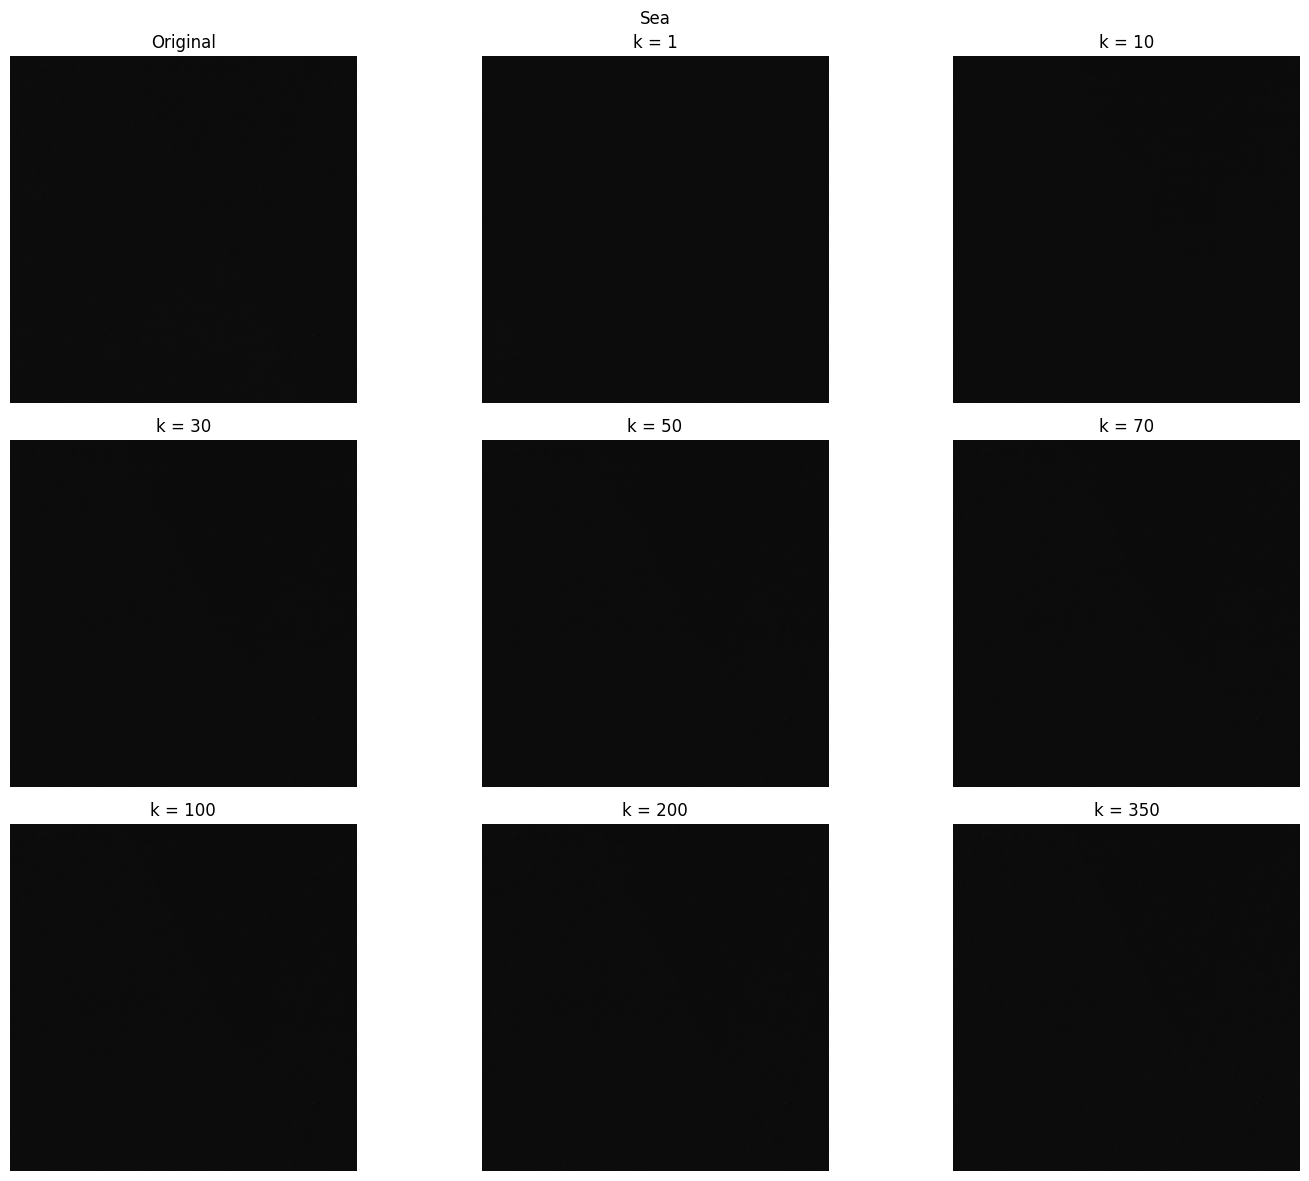

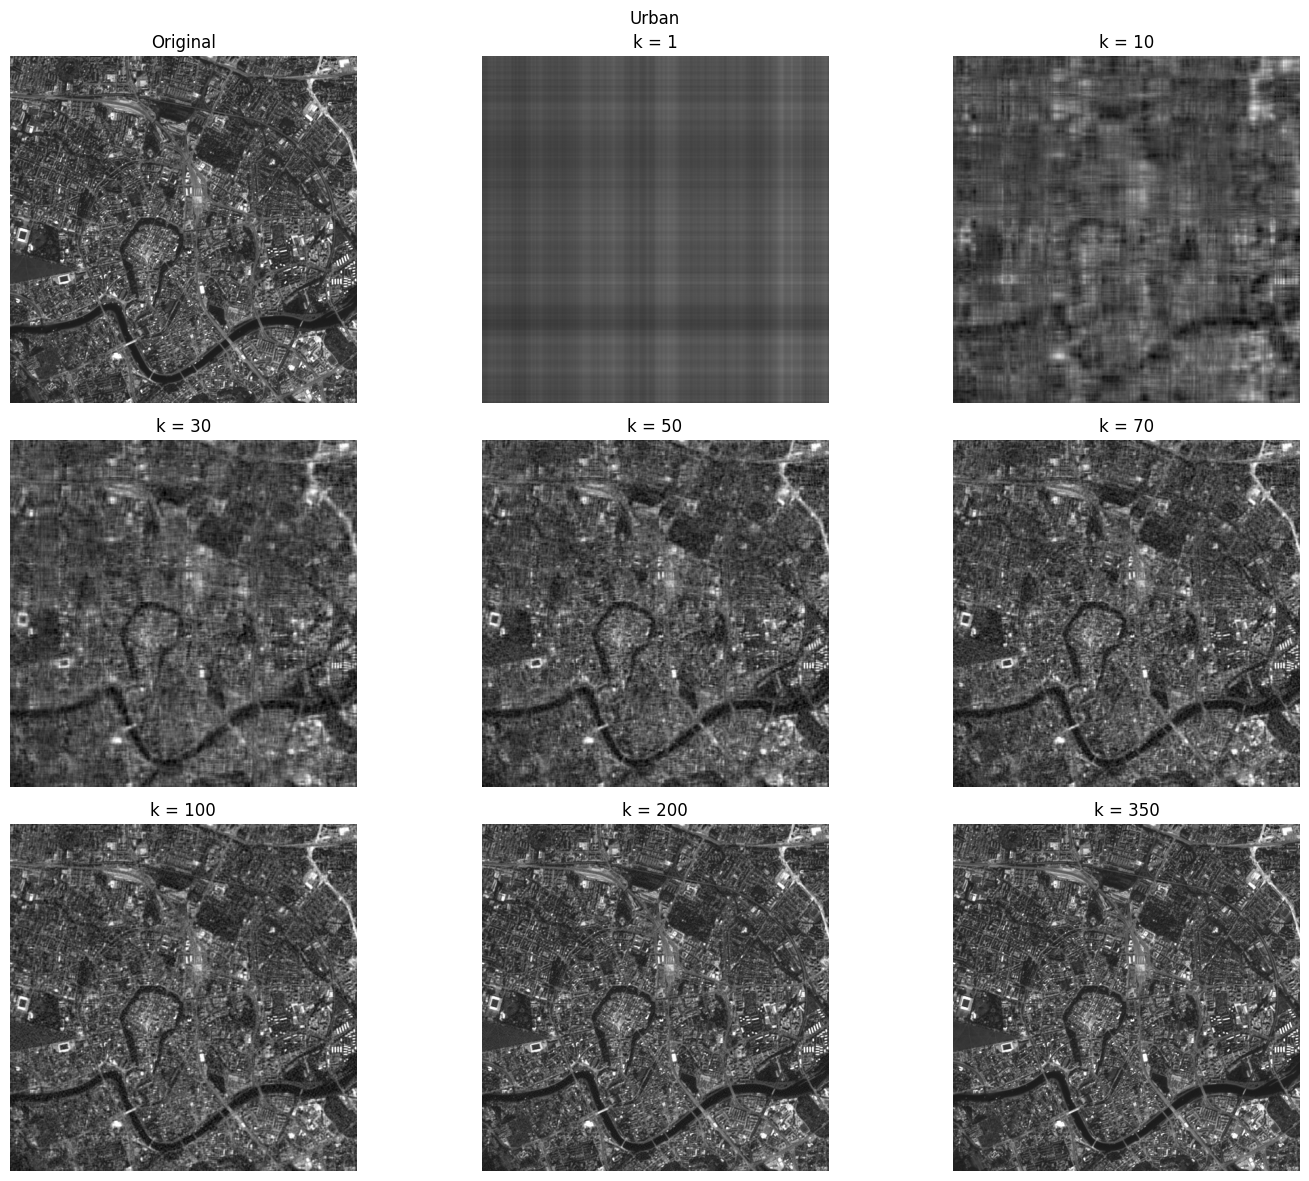

In [29]:
k_values = [1, 10, 30, 50, 70, 100, 200, 350]

for name, imgmat in images.items():
    U, sigma, V = np.linalg.svd(imgmat)

    plt.figure(figsize=(15, 12))

    plt.subplot(3, 3, 1)
    plt.imshow(imgmat, cmap='gray', vmin=0, vmax=255)
    plt.title("Original")

    for n, i in enumerate(k_values):
        reconstimg = np.matrix(U[:, :i]) * np.diag(sigma[:i]) * np.matrix(V[:i, :])

        plt.subplot(3, 3, n + 2)
        plt.imshow(reconstimg, cmap='gray', vmin=0, vmax=255)
        plt.title(f"k = {i}")

    for ax in plt.gcf().axes:
        ax.axis('off')

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

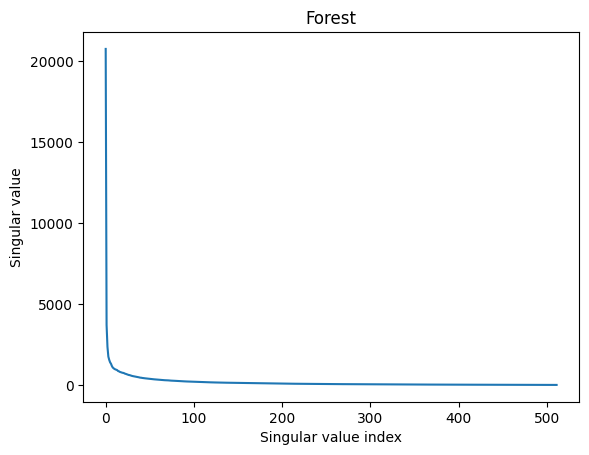

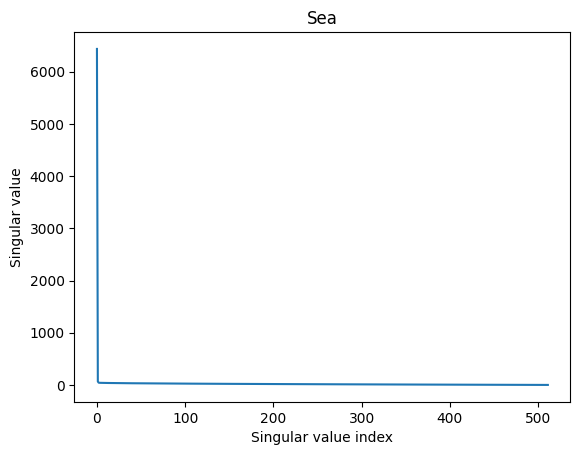

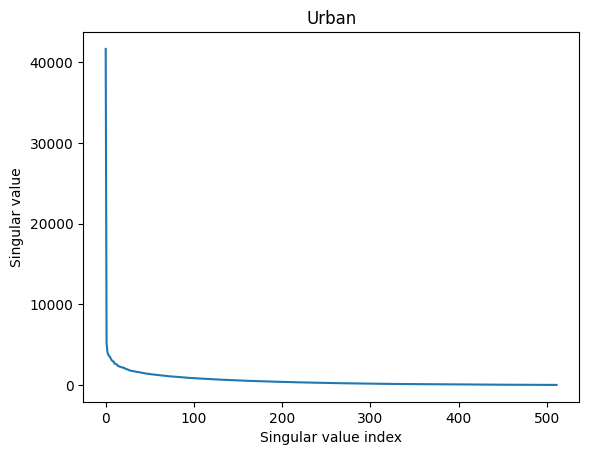

In [31]:
for name, imgmat in images.items():
    U, sigma, V = np.linalg.svd(imgmat)

    plt.plot(sigma)
    plt.title(name)
    plt.xlabel("Singular value index")
    plt.ylabel("Singular value")
    plt.show()

## Influence of eigenvalues used on quality

As it can be noted the number of eigenvalues that are required to use in order to retrieve the maximum quality varies between areas that are shown so **how many Eigen values are good enough (first task)** depends. For the sea area mostly because of how dark it was the lower values were sufficient, it's represented well on the sharp fall of values in the chart above - `k=4` should be fully sufficient for this particular scene, for forest and urban higher values need to be used as represented by the charts above, the more details the higher the value need to be in order to reconstruct the details - for urban I would say that `k=70` yields acceptable results, for forest `k=40` should be enough due to lower number of detials in the image. These observations hold for **Load satellite images of different terrains (forest vs urban vs ocean etc.). Note how many Eigen values are enough to capture the original image without perceptual degradation. Note on your observations.** as well, of course the values are a bit approximated, but I believe that the overall trend/direction is well captured by those numbers

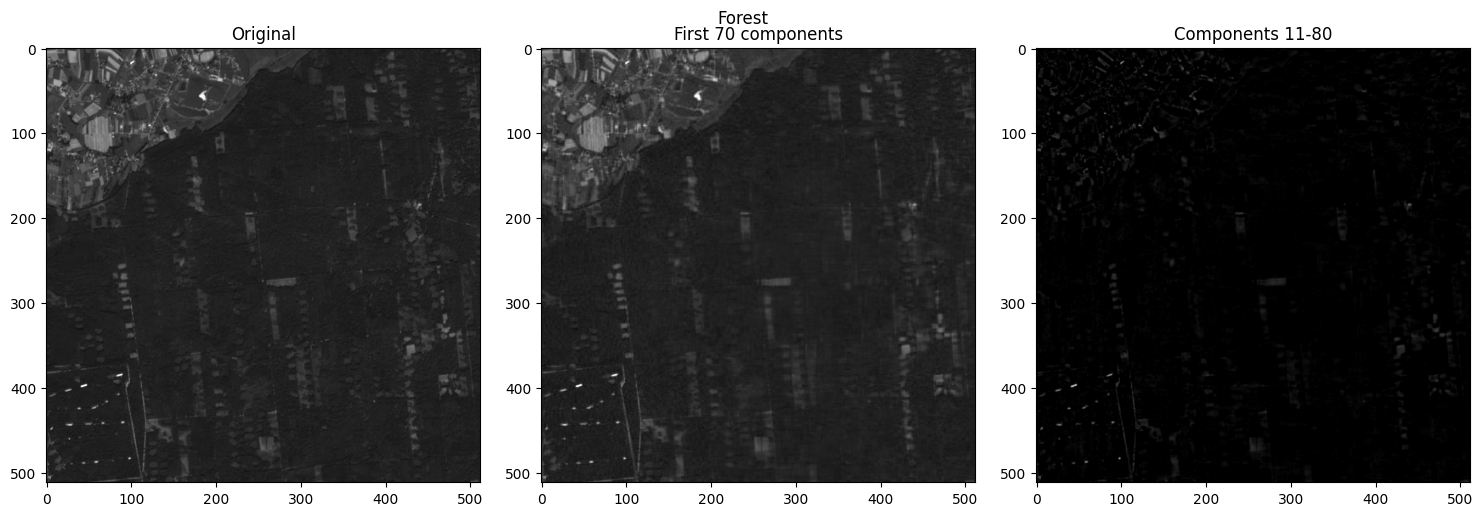

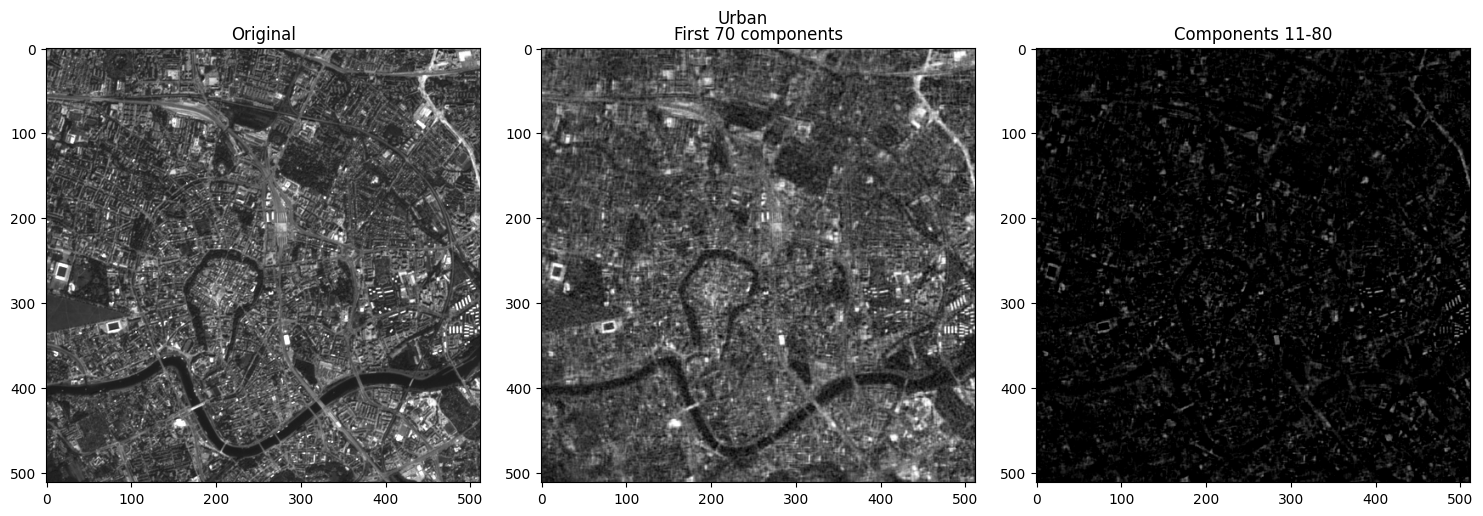

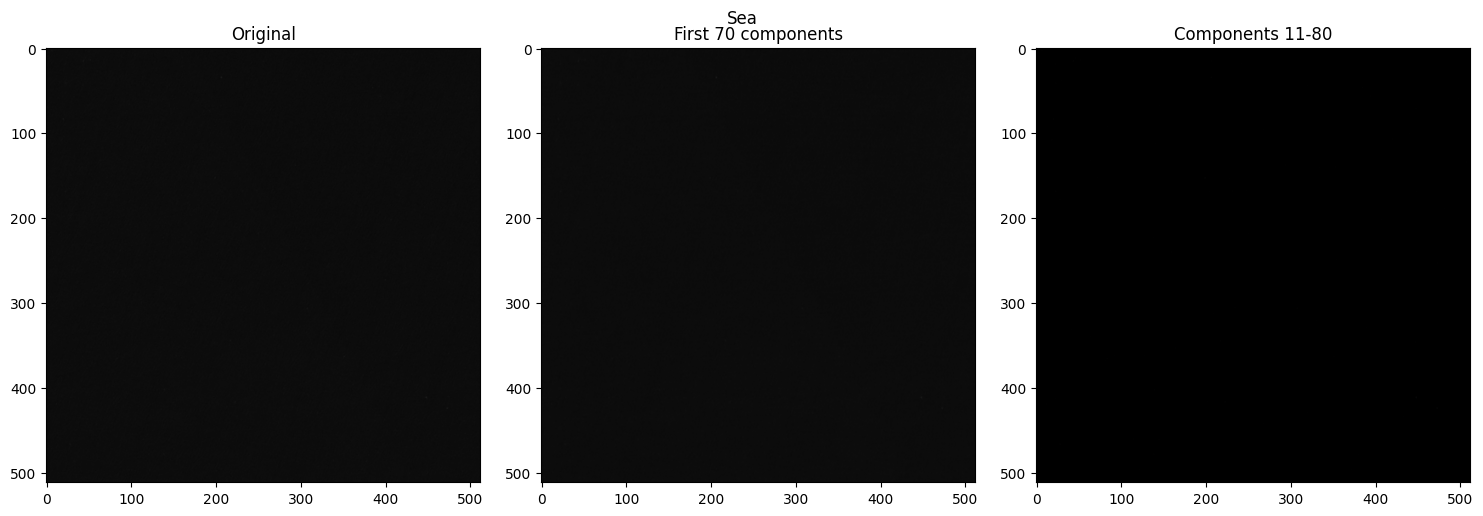

In [18]:
for name, imgmat in images.items():
    U, sigma, V = np.linalg.svd(imgmat)

    i = 70
    j = 0

    reconstimg1 = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])

    i = 80
    j = 10

    reconstimg2 = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(imgmat, cmap='gray', vmin=0, vmax=255)
    plt.title("Original")

    plt.subplot(1, 3, 2)
    plt.imshow(reconstimg1, cmap='gray', vmin=0, vmax=255)
    plt.title("First 70 components")

    plt.subplot(1, 3, 3)
    plt.imshow(reconstimg2, cmap='gray', vmin=0, vmax=255)
    plt.title("Components 11-80")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

**In stead of using the largest $k$ Eigen values, if you use 10th, 11th,,,,k+10 engine values, would you get better images?** Again depending on the details captured by the scene, it can be either enough (sea), almost enough forest (it's much darker but generally the most important details are visible), or completely insuffiencient (urban), here only some of the details are restored, but generally speaking the scene is unreadable. I added the first 70 eigenvalues/components for further analysis of my previous point